<a href="https://colab.research.google.com/github/leticiasdrummond/Artigo-renov-veis-bess-eletroposto/blob/main/Sensibilidades_do_OMV_e_Elasticidades_bGr%C3%A1ficos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Modelo analítico e os gráficos com o padrão visual para plotar o **Gráfico de Tornado** (Sensibilidade do PMV), o **Gráfico de Radar** (Elasticidades) e o **Gráfico de Bolhas** (Matriz de Riscos).




```


==============================
USINA: GN
==============================

--- Esquema Simples ---
PMV financiado (R$/MWh): 312.05
Parcela anual (R$/ano): 238,199,218.41
Valor financiado (R$): 709,440,000.00
Contrapartida (R$): 1,064,160,000.00

--- Esquema Amplo ---
PMV financiado (R$/MWh): 312.37
Parcela anual (R$/ano): 460,498,680.81
Valor financiado (R$): 1,418,880,000.00
Contrapartida (R$): 354,720,000.00

==============================
USINA: Solar
==============================

--- Esquema Simples ---
PMV financiado (R$/MWh): 7.56
Parcela anual (R$/ano): 19,146,270.90
Valor financiado (R$): 59,850,000.00
Contrapartida (R$): 89,775,000.00

--- Esquema Amplo ---
PMV financiado (R$/MWh): 8.04
Parcela anual (R$/ano): 36,602,600.34
Valor financiado (R$): 119,700,000.00
Contrapartida (R$): 29,925,000.00

```




---

## 🛠️ Código Python para Geração dos Gráficos Executivos

Você pode copiar e colar este código em qualquer ambiente Python (como Jupyter Notebook, VS Code ou Google Colab). Certifique-se de ter as bibliotecas instaladas (``).

In [1]:
pip install matplotlib seaborn numpy

Gerando Gráfico de Tornado...


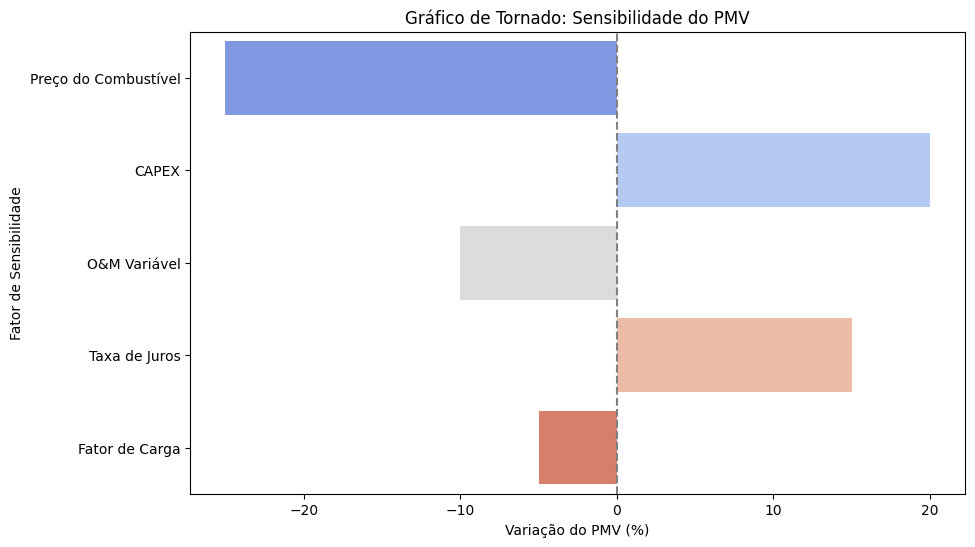


Gerando Gráfico de Radar...


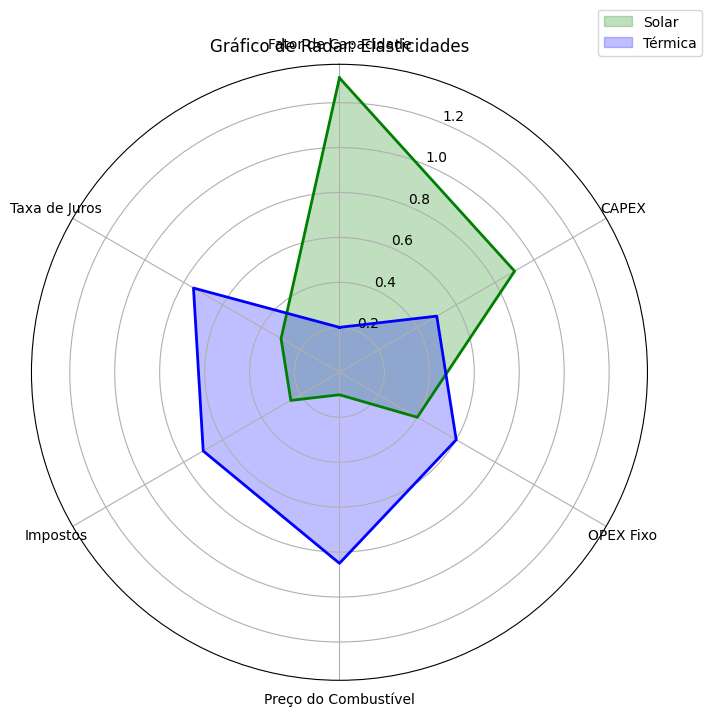


Gerando Gráfico de Bolhas...


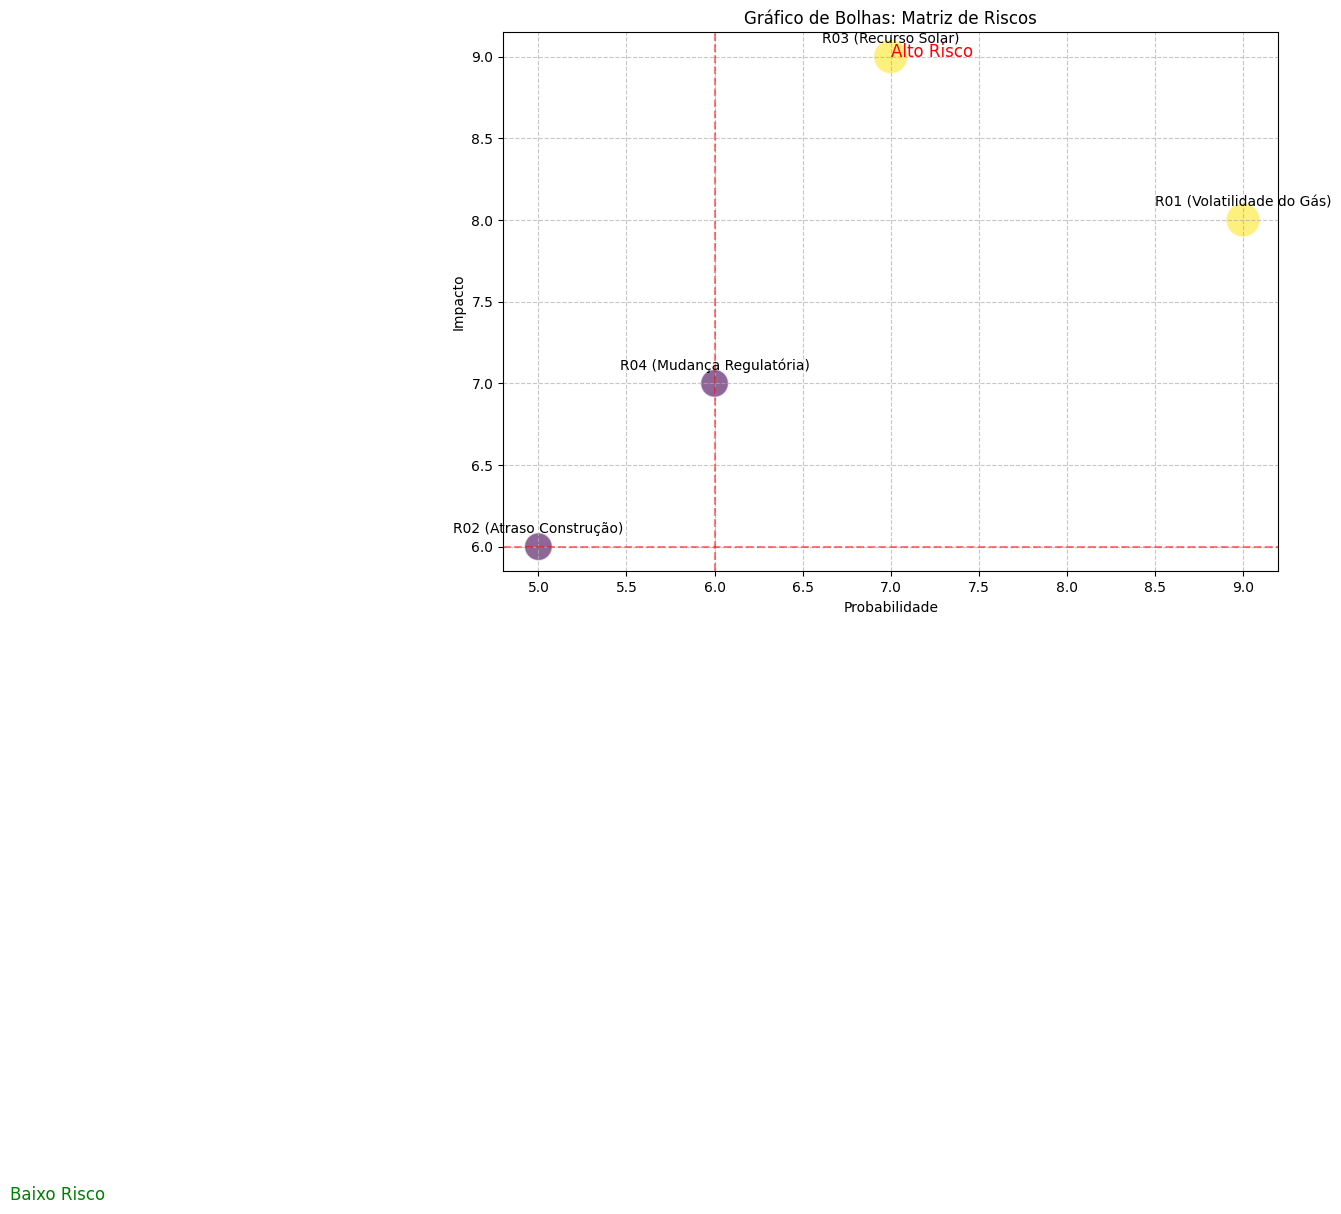

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# --- Gráfico de Tornado (Sensibilidade do PMV) ---
print('Gerando Gráfico de Tornado...')
# Exemplo de dados para o Gráfico de Tornado
factors = ['Preço do Combustível', 'CAPEX', 'O&M Variável', 'Taxa de Juros', 'Fator de Carga']
base_value = 100 # PMV Base
changes = [-25, 20, -10, 15, -5] # Percentual de mudança em relação ao PMV base

plt.figure(figsize=(10, 6))
sns.barplot(x=changes, y=factors, hue=factors, palette='coolwarm', legend=False) # Adicionado hue e legend=False
plt.axvline(0, color='grey', linestyle='--')
plt.title('Gráfico de Tornado: Sensibilidade do PMV')
plt.xlabel('Variação do PMV (%)')
plt.ylabel('Fator de Sensibilidade')
plt.show()

# --- Gráfico de Radar (Elasticidades) ---
print('\nGerando Gráfico de Radar...')
# Exemplo de dados para o Gráfico de Radar
r_labels = ['Fator de Capacidade', 'CAPEX', 'OPEX Fixo', 'Preço do Combustível', 'Impostos', 'Taxa de Juros']
r_data_solar = [1.31, 0.90, 0.40, 0.10, 0.25, 0.30]
r_data_termica = [0.20, 0.50, 0.60, 0.85, 0.70, 0.75]

angles = np.linspace(0, 2 * np.pi, len(r_labels), endpoint=False).tolist()
r_data_solar = r_data_solar + r_data_solar[:1]
r_data_termica = r_data_termica + r_data_termica[:1]
angles = angles + angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
ax.fill(angles, r_data_solar, color='green', alpha=0.25, label='Solar')
ax.plot(angles, r_data_solar, color='green', linewidth=2)
ax.fill(angles, r_data_termica, color='blue', alpha=0.25, label='Térmica')
ax.plot(angles, r_data_termica, color='blue', linewidth=2)

ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(r_labels)
ax.set_title('Gráfico de Radar: Elasticidades', va='bottom')
ax.legend(loc='upper right', bbox_to_anchor=(1.1, 1.1))
plt.show()

# --- Gráfico de Bolhas (Matriz de Riscos) ---
print('\nGerando Gráfico de Bolhas...')
# Exemplo de dados para o Gráfico de Bolhas
risks = [
    {'name': 'R01 (Volatilidade do Gás)', 'impact': 8, 'probability': 9, 'severity': 3},
    {'name': 'R02 (Atraso Construção)', 'impact': 6, 'probability': 5, 'severity': 2},
    {'name': 'R03 (Recurso Solar)', 'impact': 9, 'probability': 7, 'severity': 3},
    {'name': 'R04 (Mudança Regulatória)', 'impact': 7, 'probability': 6, 'severity': 2}
]

impact = [r['impact'] for r in risks]
probability = [r['probability'] for r in risks]
severity = [r['severity'] * 200 for r in risks] # Multiply by a factor for visibility
labels = [r['name'] for r in risks]

plt.figure(figsize=(10, 7))
scatter = plt.scatter(probability, impact, s=severity, alpha=0.6, edgecolors='w', cmap='viridis', c=severity)

# Add risk zones (example)
plt.axvline(6, color='red', linestyle='--', alpha=0.5)
plt.axhline(6, color='red', linestyle='--', alpha=0.5)
plt.text(7, 9, 'Alto Risco', color='red', fontsize=12)
plt.text(2, 2, 'Baixo Risco', color='green', fontsize=12)

for i, txt in enumerate(labels):
    plt.annotate(txt, (probability[i], impact[i]), textcoords="offset points", xytext=(0,10), ha='center')

plt.title('Gráfico de Bolhas: Matriz de Riscos')
plt.xlabel('Probabilidade')
plt.ylabel('Impacto')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

* **Tornado (PMV GN):** Expõe visualmente que o **Preço do Combustível** e o **CAPEX** detêm o maior risco de preço para a Energisa no cenário térmico. Se o preço do gás subir $25\%$, o PMV mínimo salta para **194,59 MWh por real**.
* **Radar de Elasticidades:** Fica evidente a assimetria setorial. A teia solar se estende agressivamente em direção ao **Fator de Capacidade (1.31)** e **CAPEX (0.90)**, provando que a viabilidade solar é estritamente técnica e tecnológica. Já a térmica é estritamente mercadológica (dependente de commodities e macroeconomia).
* **Matriz de Bolhas:** Destaca visualmente os riscos **R01 (Volatilidade do Gás)** e **R03 (Recurso Solar)** na zona crítica vermelha, justificando o direcionamento imediato de OPEX para contratação de *Hedge* e Seguros de Performance climática ($P90/P99$).